<a href="https://colab.research.google.com/github/Rahul-Garg2006/DNN_Project/blob/main/defect_dataset_builder_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3D print defect dataset builder v4 (2 datasets -> 1 merged dataset)

**What this notebook does, in simple words**
1. Downloads dataset 1 (Roboflow "Defects Classification in 3D Printing") straight into Colab.
2. Downloads a **small random sample** of dataset 2 (Bast et al., 32 GB in total) straight from Zenodo, taking only the cropped images.
3. Shows you what is inside both, so you can check the class names.
4. Merges them into one dataset: same class names, no duplicates, split into **train / val / test**.
5. Saves the result as one zip file in your Google Drive, ready for the training notebook.

**How to use it:** run the cells **from top to bottom, one at a time**. Click the play button on the left of a cell and wait for the green tick before running the next one. The cell marked **YOU MAY EDIT THIS** is the only one where you might need to change something.

You do **not** need a GPU for this notebook.

## Step 1: Connect Google Drive and set the folders
A popup will ask for permission to use your Google Drive. Click **Connect to Google Drive** and then **Allow**.
- **Google Drive** (`defect_project` folder): permanent. The final merged dataset is saved here.
- **Colab disk** (`/content/work`): fast but temporary. It is wiped when the Colab session ends, so in a new session just run the steps again (they are quick) or use the zip saved in Drive.

In [ ]:
import os, re, csv, shutil, hashlib, zipfile, collections
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab, skipping the Drive mount.')

DRIVE = Path(os.environ.get('DEFECT_DRIVE', '/content/drive/MyDrive/defect_project'))
WORK  = Path(os.environ.get('DEFECT_WORK',  '/content/work'))
RAW   = WORK / 'raw'        # downloaded datasets, one folder each
STAGE = WORK / 'staging'    # renamed copies, one folder per class (rebuilt every run)
OUT   = WORK / 'merged'     # final train/val/test folders (rebuilt every run)

for p in (DRIVE, RAW):
    p.mkdir(parents=True, exist_ok=True)

DATASETS = ['defcls', 'bast']   # folder names inside RAW. defcls = dataset 1, bast = dataset 2
print('Google Drive folder :', DRIVE)
print('Working folder      :', WORK)

Mounted at /content/drive
Google Drive folder : /content/drive/MyDrive/defect_project
Working folder      : /content/work


## Step 2: Download dataset 1 from Roboflow
- You need your Roboflow **API key** (Settings in your Roboflow account). When you run the cell, paste it into the small hidden box and press Enter. It is not saved in the notebook. Never share it.
- If you get a **version not found** error, change `ROBOFLOW_VERSION` below (on the dataset page click *Download Dataset*, choose *Folder Structure*, then *Show download code*, and copy the version number).
- It takes about a minute.

In [ ]:
%pip install -q roboflow
from getpass import getpass
from roboflow import Roboflow

ROBOFLOW_WORKSPACE = 'project-jkfnh'
ROBOFLOW_PROJECT   = 'defects-classification-in-3d-printing-fwsu3'
ROBOFLOW_VERSION   = 1          # <- change this if you get a "version not found" error

dest = RAW / 'defcls'
if dest.exists() and len(list(dest.rglob('*.*'))) > 10:
    print('Already downloaded:', dest)
else:
    key = getpass('Paste your Roboflow API key here and press Enter: ')
    rf = Roboflow(api_key=key)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    project.version(ROBOFLOW_VERSION).download('folder', location=str(dest))
    print('Downloaded to', dest)

Paste your Roboflow API key here and press Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/raw/defcls in folder:: 100%|██████████| 11235/11235 [00:04<00:00, 2344.77it/s]

Downloaded to /content/work/raw/defcls


## Step 3: Download a sample of dataset 2 (Bast et al.) from Zenodo
The full dataset is 32 GB and has about 110,000 + 40,000 photos. We do **not** need all of them, because consecutive photos from a printer camera look almost the same. So this cell:
- reads the list of files inside the two big zips on Zenodo **without downloading them**,
- picks a **random sample** of the **cropped** images, **the same number for each class and spread evenly over the 3 cameras** (the `full_res` folders hold the same photos in full size, so we skip them),
- downloads only those files (about 2,850 in total), and retries any that fail.

`base_data.zip` will be used for training and validation. `test_data.zip` (a separate set by the authors) will be used only for the test set.

The progress bar shows how it is going. I do not know how fast Zenodo will be for you. If it looks too slow (for example, more than about an hour), stop the cell with the square button, lower the two numbers below, and run it again. It skips files it already downloaded.

In [ ]:
%pip install -q remotezip
import random, time, threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
from remotezip import RemoteZip

BAST = {
    'base_data': dict(url='https://zenodo.org/records/14712897/files/base_data.zip?download=1', per_class=700),
    'test_data': dict(url='https://zenodo.org/records/14712897/files/test_data.zip?download=1', per_class=250),
}
WORKERS = 6      # how many files are downloaded at the same time
SEED = 42
bast_root = RAW / 'bast'

def class_and_camera(name):
    # path looks like  base/cropped/<class>/<camera>/<file>.jpg
    parts = Path(name).parts
    i = [p.lower() for p in parts].index('cropped')
    cls = parts[i + 1]
    cam = parts[i + 2] if len(parts) > i + 3 else 'none'
    return cls, cam

def pick_files(url, per_class):
    with RemoteZip(url) as z:
        names = [i.filename for i in z.infolist() if not i.is_dir() and '/cropped/' in i.filename.replace('\\', '/')]
    groups = collections.defaultdict(list)
    for n in names:
        groups[class_and_camera(n)].append(n)
    rnd = random.Random(SEED)
    chosen = []
    for c in sorted({c for c, _ in groups}):
        cams = sorted(cam for cc, cam in groups if cc == c)
        quota = per_class // len(cams)
        got, avail = 0, 0
        for cam in cams:
            ns = sorted(groups[(c, cam)])
            k = min(quota, len(ns))
            chosen += rnd.sample(ns, k)
            got += k
            avail += len(ns)
        print(f'    {c}: {avail} available, taking {got} (from {len(cams)} cameras)')
    return chosen

_tl = threading.local()
def fetch_one(url, name):
    out = bast_root / name
    if out.exists() and out.stat().st_size > 0:
        return True
    for attempt in range(5):
        try:
            if not hasattr(_tl, 'zips'):
                _tl.zips = {}
            if url not in _tl.zips:
                _tl.zips[url] = RemoteZip(url)
            _tl.zips[url].extract(name, path=str(bast_root))
            return True
        except Exception:
            _tl.zips = {}          # reconnect on the next try
            time.sleep(2 * (attempt + 1))
    return False

def run_jobs(job_list, workers, label):
    bad = []
    with ThreadPoolExecutor(workers) as ex:
        futs = {ex.submit(fetch_one, u, n): (u, n) for u, n in job_list}
        for f in tqdm(as_completed(futs), total=len(futs), desc=label):
            if not f.result():
                bad.append(futs[f])
    return bad

jobs = []
for tag, cfg in BAST.items():
    print(f'{tag}: reading the file list ...')
    for n in pick_files(cfg['url'], cfg['per_class']):
        jobs.append((cfg['url'], n))
print(f'Downloading {len(jobs)} files with {WORKERS} workers ...')

failed = run_jobs(jobs, WORKERS, 'downloading')
if failed:
    print(f'{len(failed)} downloads failed. Trying those again, more slowly ...')
    failed = run_jobs(failed, 2, 'retrying')
print(f'Done. Failed downloads: {len(failed)} of {len(jobs)}')

base_data: reading the file list ...
    extrusion_error_print: 14866 available, taking 699 (from 3 cameras)
    layershift_error_print: 14095 available, taking 699 (from 3 cameras)
    no_error_print: 26465 available, taking 699 (from 3 cameras)
test_data: reading the file list ...
    extrusion_error_print: 7006 available, taking 249 (from 3 cameras)
    layershift_error_print: 6700 available, taking 249 (from 3 cameras)
    no_error_print: 6435 available, taking 249 (from 3 cameras)


downloading:   0%|          | 0/2844 [00:00<?, ?it/s]

13 downloads failed. Trying those again, more slowly ...


retrying:   0%|          | 0/13 [00:00<?, ?it/s]

Done. Failed downloads: 0 of 2844


## Step 4: Look inside both datasets (this cell only reads, it changes nothing)
It prints every folder that contains images and how many images are in it. **Copy the printed text and send it to me.**

In [ ]:
from PIL import Image

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
SPLIT_NAMES = {'train', 'val', 'valid', 'validation', 'test'}

def norm(s):
    # 'Blobs and Zits' -> 'blobs_and_zits' (the form used as keys in LABEL_MAP below)
    return re.sub(r'[^a-z0-9]+', '_', str(s).lower()).strip('_')

def summarize(root, max_lines=70):
    imgs = [p for p in root.rglob('*') if p.suffix.lower() in IMG_EXT]
    counts = collections.Counter(str(p.parent.relative_to(root)) for p in imgs)
    print(f'  total images: {len(imgs)}')
    lines = sorted(counts.items())
    for d, n in lines[:max_lines]:
        print(f'  {n:6d}  {d}')
    if len(lines) > max_lines:
        print(f'  ... and {len(lines) - max_lines} more folders')
    print('  example file names:', [p.name for p in sorted(imgs)[:3]])

for ds in DATASETS:
    print(f'\n=== {ds} ===')
    if not (RAW / ds).exists():
        print('  folder missing (did the earlier step run?)')
        continue
    summarize(RAW / ds)


=== defcls ===
  total images: 11233
     119  test/Bed Adhesion
     104  test/Blob of Death
      95  test/Blobs and Zits
      95  test/Layer Separation
     104  test/Layer Shifting
      94  test/No Defect
     105  test/Nozzle Clog
      41  test/Over Extrusion
      93  test/Spaghetti
      95  test/Stringing
      95  test/Under Extrusion
      94  test/Warping
     864  train/Bed Adhesion
     792  train/Blob of Death
     903  train/Blobs and Zits
     800  train/Layer Separation
     867  train/Layer Shifting
     828  train/No Defect
     891  train/Nozzle Clog
     810  train/Over Extrusion
     821  train/Spaghetti
     853  train/Stringing
     831  train/Under Extrusion
     839  train/Warping
  example file names: ['-2025-07-23-150034_jpg.rf.958f44ac48524cae992db7e321b3deff.jpg', '-2025-07-23-150045_jpg.rf.2e27c7d146a3efe13b6a371ff568ccfc.jpg', '-2025-07-23-150057_jpg.rf.dc5bd7b8c39fdc7aaa3afabde72e335d.jpg']

=== bast ===
  total images: 2844
     233  base/cropped/e

## Step 5: Class names and settings  (YOU MAY EDIT THIS)
This tells the notebook how to rename the folder names into one shared list of classes.

- `LABEL_MAP['dataset']['folder_key'] = 'final_class_name'` renames a class. `None` leaves that class out.
- `folder_key` is the folder name in lowercase with spaces and symbols turned into `_`.
- Anything not listed is skipped, and Step 6 prints what was skipped so nothing disappears silently.

**Dataset 1 (`defcls`)**: all 12 of its classes are kept (you asked for as many classes as possible). Spaghetti, nozzle clog, bed adhesion and blob of death are print failures that you see **while printing** more than on a finished part. If the example images in Step 6b show that they don't fit your project, set them to `None` again.

**Dataset 2 (`bast`)**: its folders are `extrusion_error_print`, `layershift_error_print` and `no_error_print`. I mapped them to `extrusion_error`, `layer_shift` and `good`. `CLASS_LEVEL` says the class is the 3rd folder level (`base/cropped/<class>`).
Note that Bast's `extrusion_error` may overlap in meaning with `over_extrusion` and `under_extrusion` from dataset 1, and I have not seen what its images show. Look at the example images in Step 6 before you trust that class. If it looks confusing, set it to `None`.

**Splits**: images from Bast's `test_data` (the authors' separate test set) always go to the **test** split, and Bast's `base_data` images are only used for train/val, because photos from one printer camera are so similar that a random split would inflate the accuracy.

In [ ]:
LABEL_MAP = {
    'defcls': {
        'no_defect':         'good',
        'blobs_and_zits':    'blobs_zits',
        'layer_separation':  'layer_separation',
        'layer_shifting':    'layer_shift',
        'over_extrusion':    'over_extrusion',
        'under_extrusion':   'under_extrusion',
        'stringing':         'stringing',
        'warping':           'warping',
        'z_banding':         'z_banding',
        'spaghetti':         'spaghetti',
        'nozzle_clog':       'nozzle_clog',
        'bed_adhesion':      'bed_adhesion',
        'blob_of_death':     'blob_of_death',
        'unlabeled':         None,
    },
    'bast': {
        'no_error_print':         'good',
        'layershift_error_print': 'layer_shift',
        'extrusion_error_print':  'extrusion_error',   # in Bast this looks like tangled filament (spaghetti-like); the model's confusion matrix will tell us later whether to merge it with 'spaghetti'
    },
}

CLASS_LEVEL = {'bast': 2}                       # class = 3rd folder level inside the dataset folder
INCLUDE_IF_PATH_CONTAINS = {'bast': ['cropped']}
EXCLUDE_IF_PATH_CONTAINS = {}
GROUP_REGEX = {}

# images of these datasets whose path starts with this text always go to the TEST split
AUTHORS_TEST_PREFIX = {'bast': 'test/'}

# Step 6 compares the datasets for look-alike images. Set to True to remove the copies found in the second dataset.
DROP_CROSS_DATASET_DUPLICATES = False

## Step 6: Build the merged dataset
This cell copies every image you kept into one place, with the new class names. It also:
- skips **exact duplicate files** (also across the two datasets),
- records a small "fingerprint" of each image, so it can warn you when the **same photo appears in both datasets**,
- keeps Roboflow's augmented copies of a photo together with the original (so they cannot end up in both train and test).

At the end it prints what it skipped and any class names it could not map. If you see a list under **UNMAPPED**, go back to Step 5, add those names, and run Step 6 again.

In [ ]:
import pandas as pd

def get_class(ds, root, p):
    rel = p.relative_to(root).parts[:-1]          # folder names between the dataset root and the image
    lvl = CLASS_LEVEL.get(ds)
    if lvl is not None:
        return rel[lvl] if len(rel) > lvl else None
    c = p.parent.name
    if norm(c) in SPLIT_NAMES:
        c = p.parent.parent.name
    return c

def safe(s):
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', s)[:80]

def md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

RESAMPLE = Image.Resampling.LANCZOS if hasattr(Image, 'Resampling') else Image.LANCZOS

def dhash(im, size=8):
    # tiny 64-bit fingerprint: similar-looking images get the same (or nearly the same) value
    g = im.convert('L').resize((size + 1, size), RESAMPLE)
    px = list(g.getdata())
    bits = 0
    for r in range(size):
        for c in range(size):
            a, b = px[r * (size + 1) + c], px[r * (size + 1) + c + 1]
            bits = (bits << 1) | (1 if a > b else 0)
    return f'{bits:016x}'

def group_of(ds, src_class, stem):
    base = stem.split('.rf.')[0]                  # drop Roboflow's augmentation suffix
    rx = GROUP_REGEX.get(ds)
    if rx:
        m = re.match(rx, base)
        if m:
            base = m.group(1)
    return f'{ds}:{norm(src_class)}:{base}'

if STAGE.exists():
    shutil.rmtree(STAGE)
rows, seen_md5 = [], set()
skipped, unmapped = collections.Counter(), collections.Counter()

for ds in DATASETS:
    root = RAW / ds
    if not root.exists():
        print(f'[{ds}] folder missing, skipped')
        continue
    cmap = LABEL_MAP.get(ds, {})
    inc = [s.lower() for s in INCLUDE_IF_PATH_CONTAINS.get(ds, [])]
    exc = [s.lower() for s in EXCLUDE_IF_PATH_CONTAINS.get(ds, [])]
    for p in sorted(root.rglob('*')):
        if p.suffix.lower() not in IMG_EXT:
            continue
        rel = p.relative_to(root).as_posix()
        if (inc and not any(s in rel.lower() for s in inc)) or any(s in rel.lower() for s in exc):
            skipped['path_filter'] += 1
            continue
        src = get_class(ds, root, p)
        if src is None:
            skipped['no_class_folder'] += 1
            continue
        tgt = cmap.get(norm(src), '__unmapped__')
        if tgt == '__unmapped__':
            unmapped[(ds, src)] += 1
            continue
        if tgt is None:
            skipped['dropped_class'] += 1
            continue
        h = md5(p)
        if h in seen_md5:
            skipped['exact_duplicate'] += 1
            continue
        seen_md5.add(h)
        try:
            with Image.open(p) as im:
                dh = dhash(im)
        except Exception:
            skipped['unreadable_image'] += 1
            continue
        out = STAGE / tgt / f'{ds}__{safe(p.stem)}__{h[:6]}{p.suffix.lower()}'
        out.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, out)
        rows.append(dict(path=str(out), cls=tgt, dataset=ds, src=rel, group=group_of(ds, src, p.stem), dhash=dh))

df = pd.DataFrame(rows)
print(f'Kept {len(df)} images.  Skipped: {dict(skipped)}')
if unmapped:
    print('\nUNMAPPED (not in LABEL_MAP, so skipped). Add each one to LABEL_MAP, or map it to None to leave it out on purpose:')
    for (ds, src), n in unmapped.items():
        print(f'  {ds}: {src!r}  (key {norm(src)!r})  x{n}')
assert len(df) > 0, 'No images were kept. Check LABEL_MAP and the Step 4 output.'

# look-alike images that appear in more than one dataset
order = {d: i for i, d in enumerate(DATASETS)}
df['_o'] = df['dataset'].map(order)
per_hash = df.groupby('dhash')['dataset'].nunique()
cross = per_hash[per_hash > 1].index
print(f'\nImages with a look-alike in another dataset: {int(df["dhash"].isin(cross).sum())} '
      f'({len(cross)} fingerprints). Set DROP_CROSS_DATASET_DUPLICATES = True in Step 5 if this is a large share.')
if DROP_CROSS_DATASET_DUPLICATES and len(cross):
    first = df[df['dhash'].isin(cross)].groupby('dhash')['_o'].min()
    drop = df['dhash'].isin(cross) & (df['_o'] > df['dhash'].map(first))
    print(f'Removing {int(drop.sum())} look-alike images from the later dataset.')
    df = df[~drop]
df = df.drop(columns=['_o']).reset_index(drop=True)
print('\nImages vs distinct source photos per class (augmented copies share one source photo):')
print(df.groupby('cls').agg(images=('path', 'count'), source_photos=('group', 'nunique')))

Kept 14057 images.  Skipped: {'exact_duplicate': 20}

Images with a look-alike in another dataset: 0 (0 fingerprints). Set DROP_CROSS_DATASET_DUPLICATES = True in Step 5 if this is a large share.

Images vs distinct source photos per class (augmented copies share one source photo):
                  images  source_photos
cls                                    
bed_adhesion         983            982
blob_of_death        896            896
blobs_zits           998            932
extrusion_error      944            944
good                1867           1866
layer_separation     895            768
layer_shift         1906           1892
nozzle_clog          996            977
over_extrusion       851            786
spaghetti            914            912
stringing            948            933
under_extrusion      926            795
warping              933            929


## Step 6b: Look at example images (important, please do this)
This shows a few images of every class, **from each dataset side by side**. Look at them yourself:
- Does each row really show the defect named on its left?
- Do the two datasets look very different from each other (colour, background, camera)? If they do, the model may learn to recognise the dataset instead of the defect. We will check this later.
- Do any labels look wrong?

Send me a screenshot of this output too if anything looks odd.

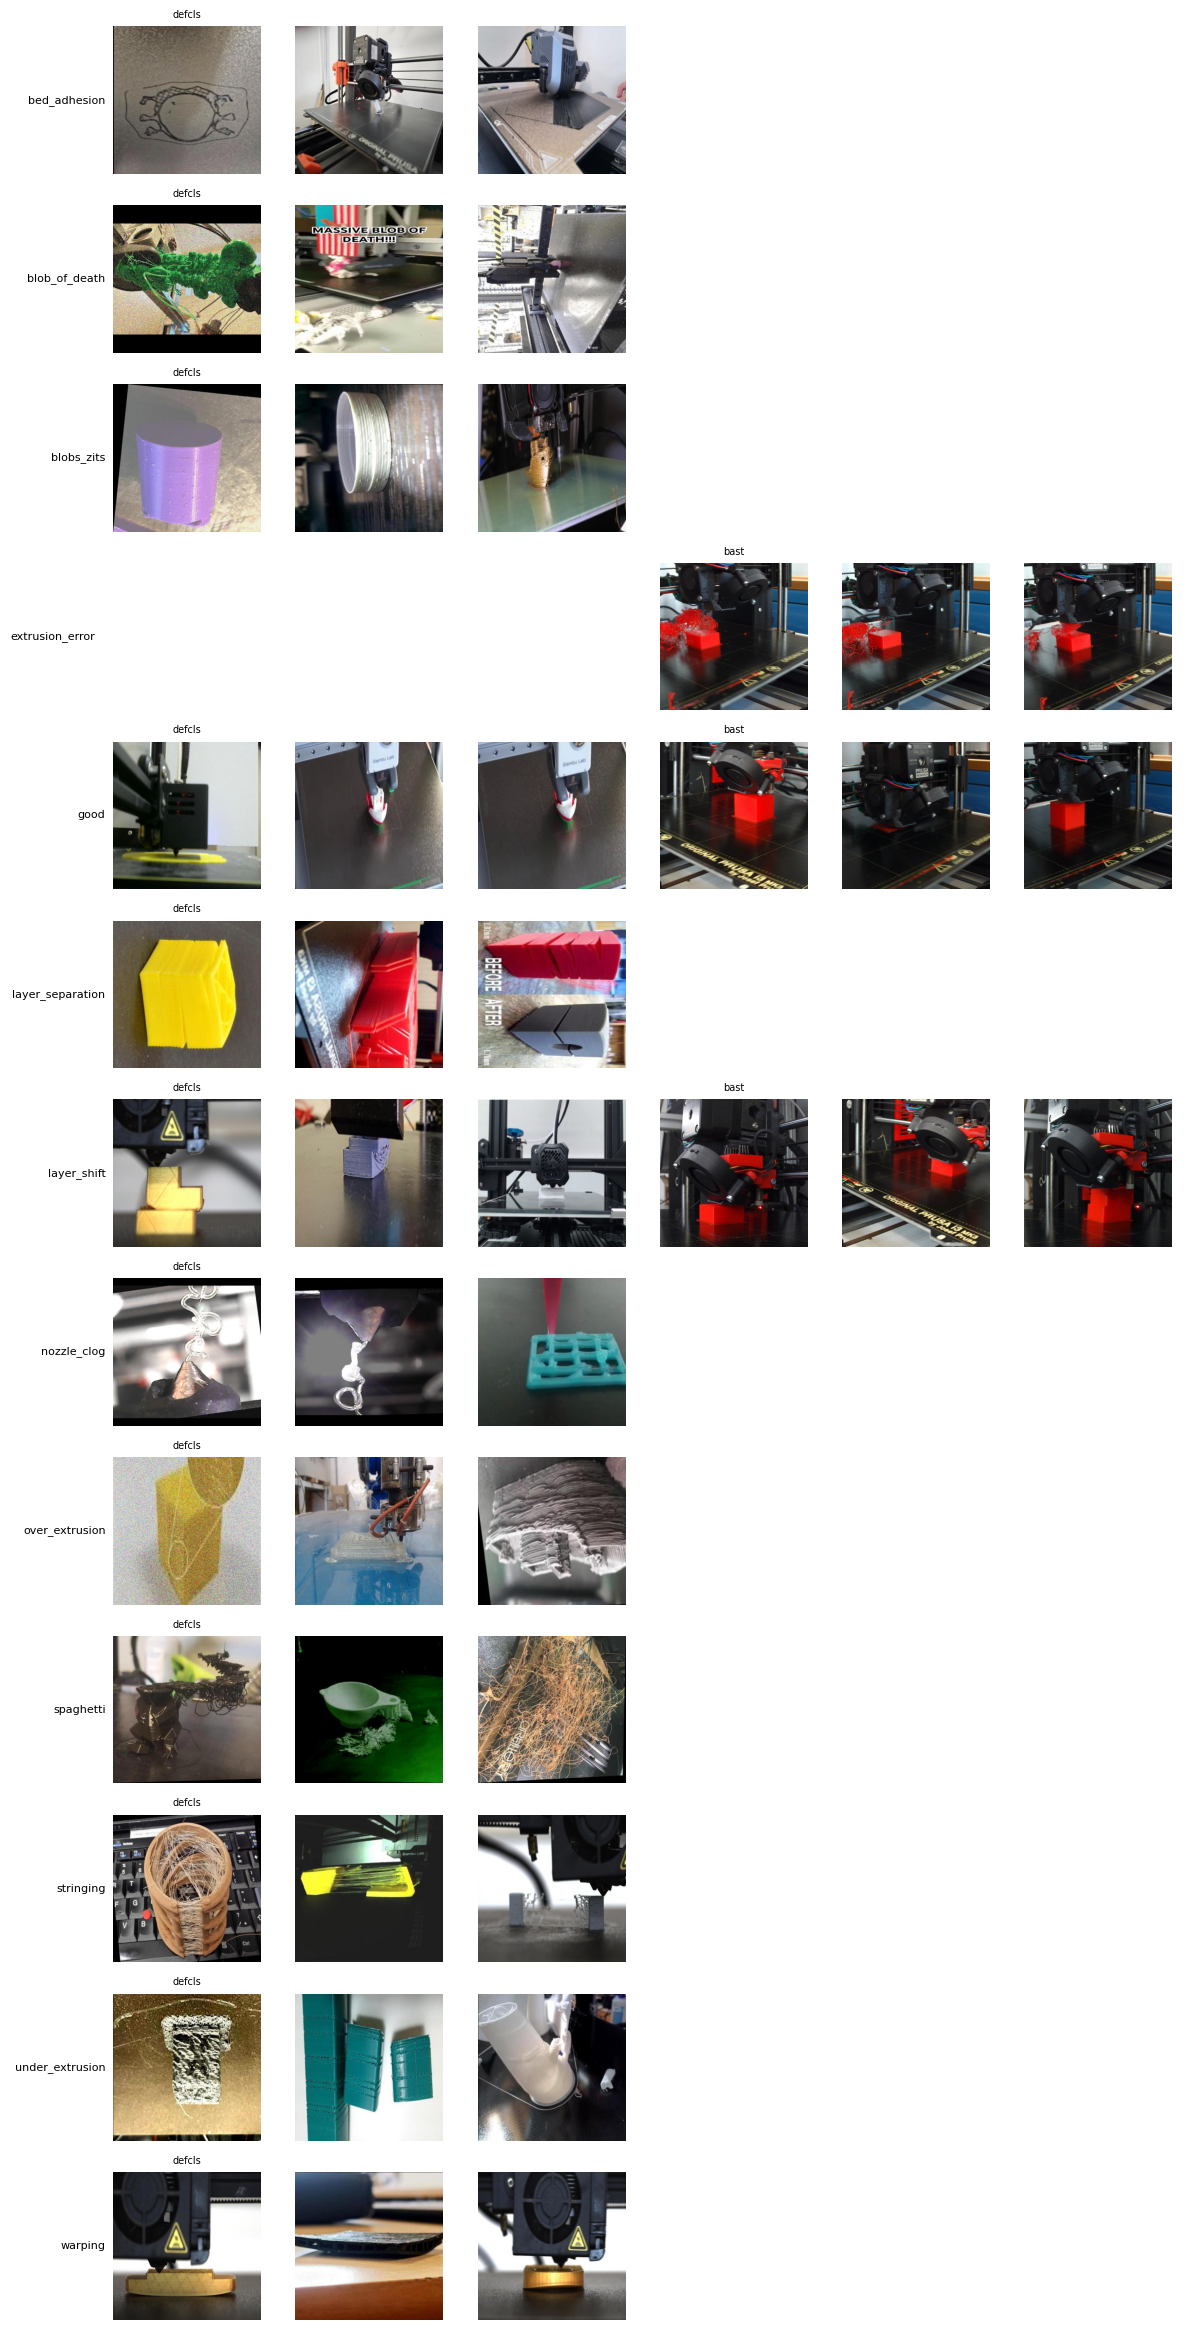

In [ ]:
import matplotlib.pyplot as plt

PER_DS = 3
classes = sorted(df['cls'].unique())
cols = PER_DS * len(DATASETS)
fig, axes = plt.subplots(len(classes), cols, figsize=(2.0 * cols, 1.8 * len(classes)), squeeze=False)
rnd = random.Random(0)
for r, c in enumerate(classes):
    for d, ds in enumerate(DATASETS):
        sub = df[(df['cls'] == c) & (df['dataset'] == ds)]
        picks = sub.sample(min(PER_DS, len(sub)), random_state=0)['path'].tolist() if len(sub) else []
        for k in range(PER_DS):
            ax = axes[r][d * PER_DS + k]
            ax.axis('off')
            if k < len(picks):
                ax.imshow(Image.open(picks[k]).convert('RGB'))
                if k == 0:
                    ax.set_title(f'{ds}', fontsize=7)
        if d == 0:
            axes[r][0].text(-0.05, 0.5, c, transform=axes[r][0].transAxes, ha='right', va='center', fontsize=8)
plt.tight_layout()
plt.show()

## Step 7: Split into train / val / test and save to Drive
- **train** (about 70 %): the model learns from these.
- **val** (about 15 %): used while training to compare settings.
- **test** (about 15 %): used once at the end to report accuracy.

Photos from the same group (same original photo and its augmented copies) always go to the same split. Bast `test_data` images always go to test, and Bast `base_data` images never go to test.

The cell prints a table of images per class and warns about classes that are too small. It then saves:
- `merged_dataset.zip` in your Drive (folders train/val/test with one subfolder per class),
- `merged_split.csv` in your Drive (which image went where and from which dataset, so we can check accuracy per dataset later).

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
folds = [te for _, te in sgkf.split(df, df['cls'], df['group'])]
df['split'] = 'train'
df.loc[folds[1], 'split'] = 'val'
df.loc[folds[0], 'split'] = 'test'

fixed_test = pd.Series(False, index=df.index)
is_authors_ds = df['dataset'].isin(list(AUTHORS_TEST_PREFIX))
for ds, prefix in AUTHORS_TEST_PREFIX.items():
    fixed_test |= (df['dataset'] == ds) & df['src'].str.lower().str.startswith(prefix.lower())
df.loc[fixed_test, 'split'] = 'test'                                   # the authors' own test images
df.loc[is_authors_ds & ~fixed_test & (df['split'] == 'test'), 'split'] = 'train'   # Bast base images never go to test

if OUT.exists():
    shutil.rmtree(OUT)
for r in df.itertuples():
    dst = OUT / r.split / r.cls / Path(r.path).name
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(r.path, dst)

table = df.pivot_table(index='cls', columns='split', values='path', aggfunc='count', fill_value=0)
table = table.reindex(columns=['train', 'val', 'test'], fill_value=0)
table['total'] = table.sum(axis=1)
print(table)
print('\nImages per dataset and class:')
print(df.groupby(['dataset', 'cls']).size().unstack(fill_value=0).T)

print()
for c, row in table.iterrows():
    if row['total'] < 50:
        print(f'WARNING: class {c!r} has only {row["total"]} images. Consider merging it or leaving it out.')
    if row['val'] == 0 or row['test'] == 0:
        print(f'WARNING: class {c!r} is missing from val or test, so its accuracy cannot be measured.')

df.assign(file=df['path'].map(lambda s: Path(s).name)).drop(columns=['path', 'dhash']).to_csv(DRIVE / 'merged_split.csv', index=False)
print('\nZipping the merged dataset to Drive (can take a few minutes)...')
shutil.make_archive(str(DRIVE / 'merged_dataset'), 'zip', OUT)
print('Saved:', DRIVE / 'merged_dataset.zip')

split             train  val  test  total
cls                                      
bed_adhesion        702  140   141    983
blob_of_death       641  127   128    896
blobs_zits          720  138   140    998
extrusion_error     594  101   249    944
good               1259  229   379   1867
layer_separation    647  123   125    895
layer_shift        1277  241   388   1906
nozzle_clog         707  142   147    996
over_extrusion      609  116   126    851
spaghetti           652  132   130    914
stringing           684  132   132    948
under_extrusion     655  136   135    926
warping             668  132   133    933

Images per dataset and class:
dataset           bast  defcls
cls                           
bed_adhesion         0     983
blob_of_death        0     896
blobs_zits           0     998
extrusion_error    944       0
good               945     922
layer_separation     0     895
layer_shift        935     971
nozzle_clog          0     996
over_extrusion       0     85

## Step 8: Folders for your own phone photos (accuracy check only)
This makes an empty folder for each class inside `defect_project/phone_test` in Drive. Later, put your phone photos of printed parts in the matching folders. They are **never used for training**, only to check the finished model.

In [ ]:
PHONE = DRIVE / 'phone_test'
for c in sorted(df['cls'].unique()):
    (PHONE / c).mkdir(parents=True, exist_ok=True)
print('Created:', PHONE)
print('Classes:', sorted(df['cls'].unique()))

Created: /content/drive/MyDrive/defect_project/phone_test
Classes: ['bed_adhesion', 'blob_of_death', 'blobs_zits', 'extrusion_error', 'good', 'layer_separation', 'layer_shift', 'nozzle_clog', 'over_extrusion', 'spaghetti', 'stringing', 'under_extrusion', 'warping']
